# Heatmaps: transcript isoform and ORF expression

One objective: see whether samples of the same group cluster together, using the normalized expression matrices the pipeline wrote in S4.

In [1]:
source("src/heatmap.R")
options(repr.plot.width = 9, repr.plot.height = 7)
results_dir <- "../LRP2_test_results"   # change to the results folder of the run
comparison  <- "HepG2_vs_K562"          # prefix of the S4 files
groups <- read_groups(file.path(results_dir, paste0(comparison, ".lr_leafcutter.groups_file.txt")))
groups

sample,group
<chr>,<chr>
ENCFF427JDY,HepG2
ENCFF483HTA,HepG2
ENCFF589SMB,HepG2
ENCFF634YSN,K562
ENCFF694INI,K562
ENCFF696GDL,K562
ENCFF763VZC,K562
ENCFF429VVB,K562


**Explanation.** The groups file lists each sample and its group. It tells the heatmap which columns to use and how to colour the group bar.

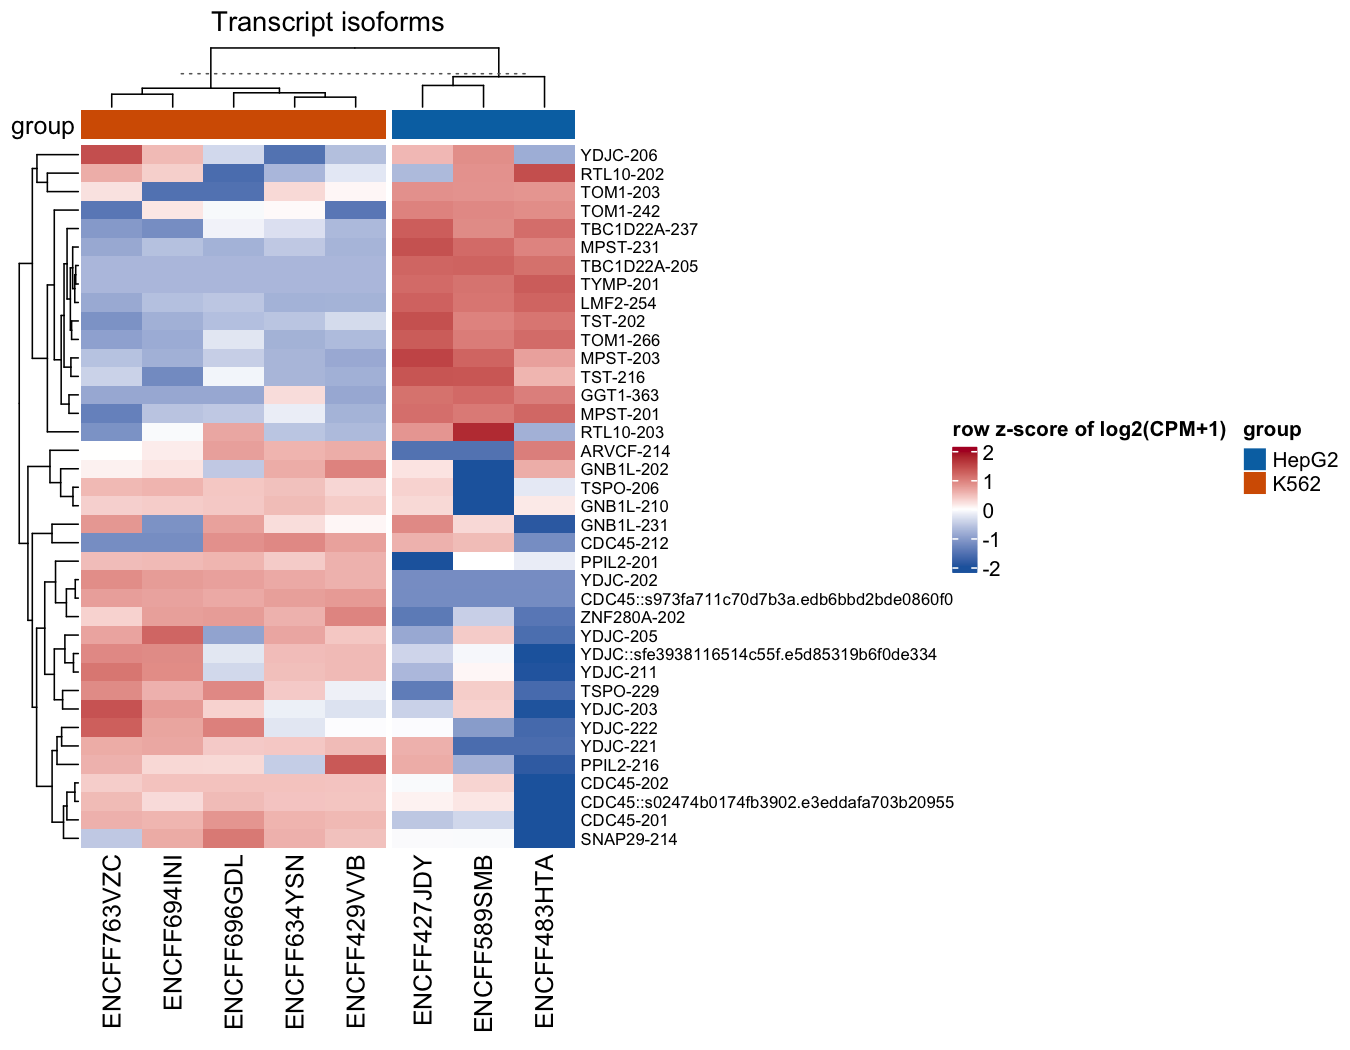

In [2]:
mat <- read_expression(file.path(results_dir, paste0(comparison, "_DTE_edgeR_normalized_CPM_matrix.txt")),
                       groups, id_col = "isoform_id", label_col = "transcript_name")
show_heatmap(expression_heatmap(mat, groups, title = "Transcript isoforms"), "isoform_heatmap")

**Explanation.** Each row is a transcript isoform, each column a sample. Values are log2(CPM + 1) with every row centred and scaled, so colour shows whether a sample is above (red) or below (blue) that isoform's average, not how large the isoform is. Rows and columns are grouped by similarity (hierarchical clustering). CPM is counts per million reads.

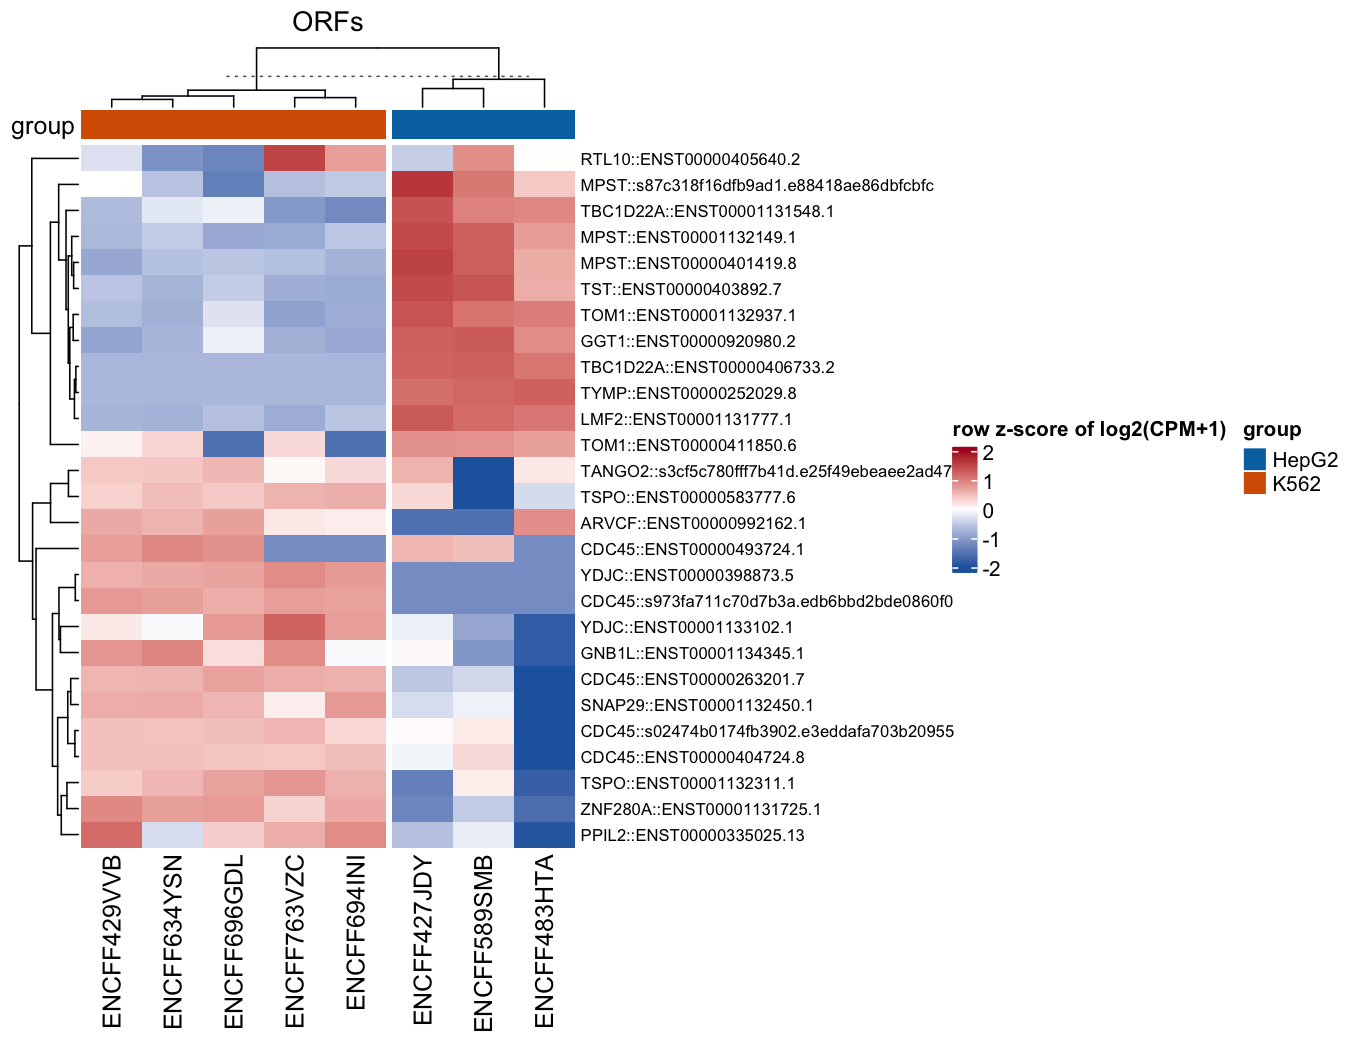

In [3]:
orf <- read_expression(file.path(results_dir, paste0(comparison, "_DE_ORF_edgeR_normalized_CPM_matrix.txt")),
                       groups, id_col = "orf_all_isoform_id", label_col = "orf_base_id")
show_heatmap(expression_heatmap(orf, groups, title = "ORFs"), "orf_heatmap")

**Explanation.** The same for open reading frames (ORFs), the predicted protein-coding stretches. Each row is an ORF named by its first transcript.